In [30]:
import pandas as pd

# Carregar o arquivo Excel para verificação
file_path = 'Rafael.xlsx'
data = pd.read_excel(file_path)

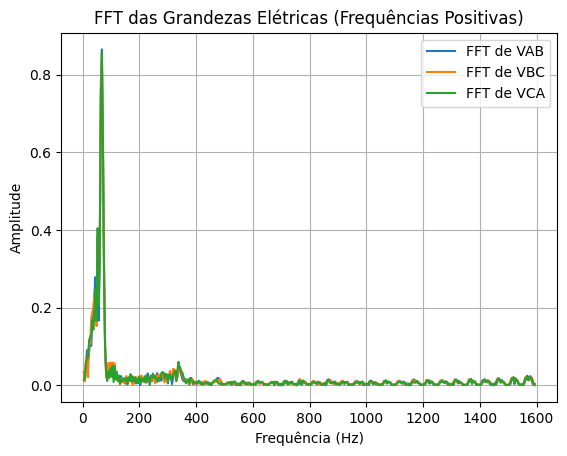

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# Remover colunas desnecessárias e valores nulos
data_clean = data[['Time', 'VAB', 'VBC', 'VCA', 'IA', 'IB', 'IC']].dropna()

# Tempo e taxa de amostragem
tempo = data_clean['Time'].values
taxa_amostragem = 1 / (tempo[1] - tempo[0])

# Função para calcular a FFT e retornar frequências e amplitudes
def calcular_fft(valores):
    fft_valores = np.fft.fft(valores)
    frequencias = np.fft.fftfreq(len(valores), d=1/taxa_amostragem)
    amplitude = 2/len(tempo) * np.abs(fft_valores)
    return frequencias, amplitude


for coluna in ['VAB', 'VBC', 'VCA']:
    frequencias, amplitude = calcular_fft(data_clean[coluna].values)
    # Filtrar para manter apenas frequências positivas
    mask = frequencias > 0
    plt.plot(frequencias[mask], amplitude[mask], label=f'FFT de {coluna}')

plt.title('FFT das Grandezas Elétricas (Frequências Positivas)')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()


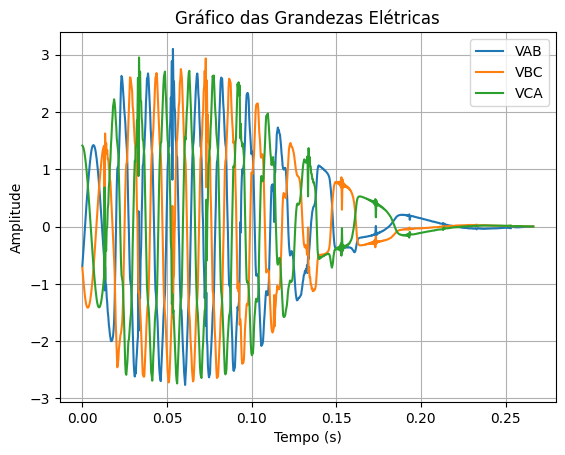

In [32]:

plt.plot(tempo, data_clean.VAB, label='VAB')
plt.plot(tempo, data_clean.VBC, label='VBC')
plt.plot(tempo, data_clean.VCA, label='VCA')
plt.title('Gráfico das Grandezas Elétricas')
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

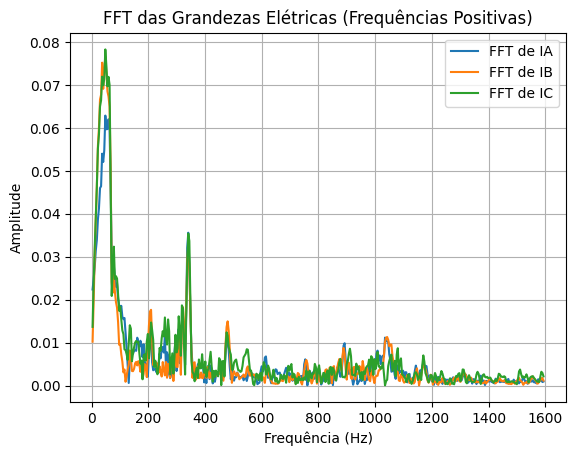

In [33]:
for coluna in ['IA', 'IB', 'IC']:
    frequencias, amplitude = calcular_fft(data_clean[coluna].values)
    # Filtrar para manter apenas frequências positivas
    mask = frequencias > 0
    plt.plot(frequencias[mask], amplitude[mask], label=f'FFT de {coluna}')

plt.title('FFT das Grandezas Elétricas (Frequências Positivas)')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

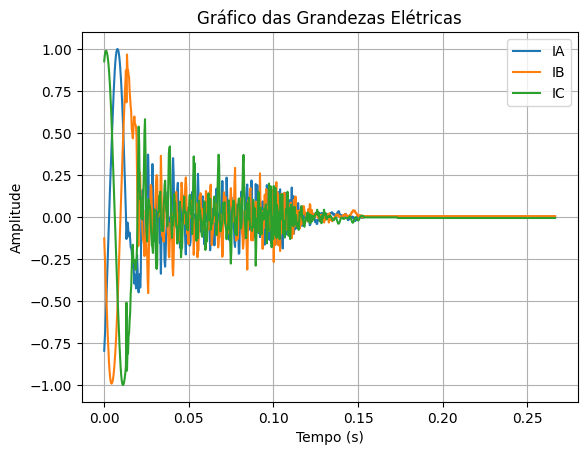

In [34]:
plt.plot(tempo, data_clean.IA, label='IA')
plt.plot(tempo, data_clean.IB, label='IB')
plt.plot(tempo, data_clean.IC, label='IC')
plt.title('Gráfico das Grandezas Elétricas')
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()